# JavaScript Error Handling

A focused introduction to error handling in JavaScript (ECMAScript 2022), covering error types, the `Error` object, `try/catch/finally`, custom error classes, and asynchronous error handling patterns.

## Table of Contents

- [Module 01: Error Handling in JavaScript](#Module-01:-Error-Handling-in-JavaScript)

In [1]:
from pathlib import Path
from IPython.display import HTML, display
import base64

def render_diagram(image_path, width=900):
    data = base64.b64encode(Path(image_path).read_bytes()).decode()
    display(HTML(f'<div style="text-align:center"><img src="data:image/png;base64,{data}" width="{width}"/></div>'))

## Module 01: Error Handling in JavaScript

_Covers the taxonomy of JavaScript errors, how runtime errors surface, and the built-in error type hierarchy — the foundation for all structured error handling._

### What Can Go Wrong?

JavaScript errors fall into four broad categories:

- **Compile time errors** — caught by the engine before execution (e.g. syntax problems in strict parsing)
- **Runtime errors** — occur during execution when an operation cannot complete (e.g. calling a non-function)
- **Syntax errors** — a subset of compile-time errors; malformed code that the parser rejects outright
- **Logic errors** — the code runs without throwing, but produces the wrong result due to a flaw in the algorithm

> In JavaScript, compile-time errors are limited compared to statically typed languages. The vast majority of errors you will encounter at runtime are `TypeError`, `ReferenceError`, or `RangeError`.

### Runtime Errors in JavaScript

A runtime error occurs when JavaScript tries to execute an operation that is not valid for the current value. The engine throws an error and, unless caught, execution halts.

The example below contains a typo: `getElemtentById` instead of `getElementById`. This is not a syntax error — it parses fine — but at runtime the property does not exist on `document`, so calling it as a function throws a `TypeError`.


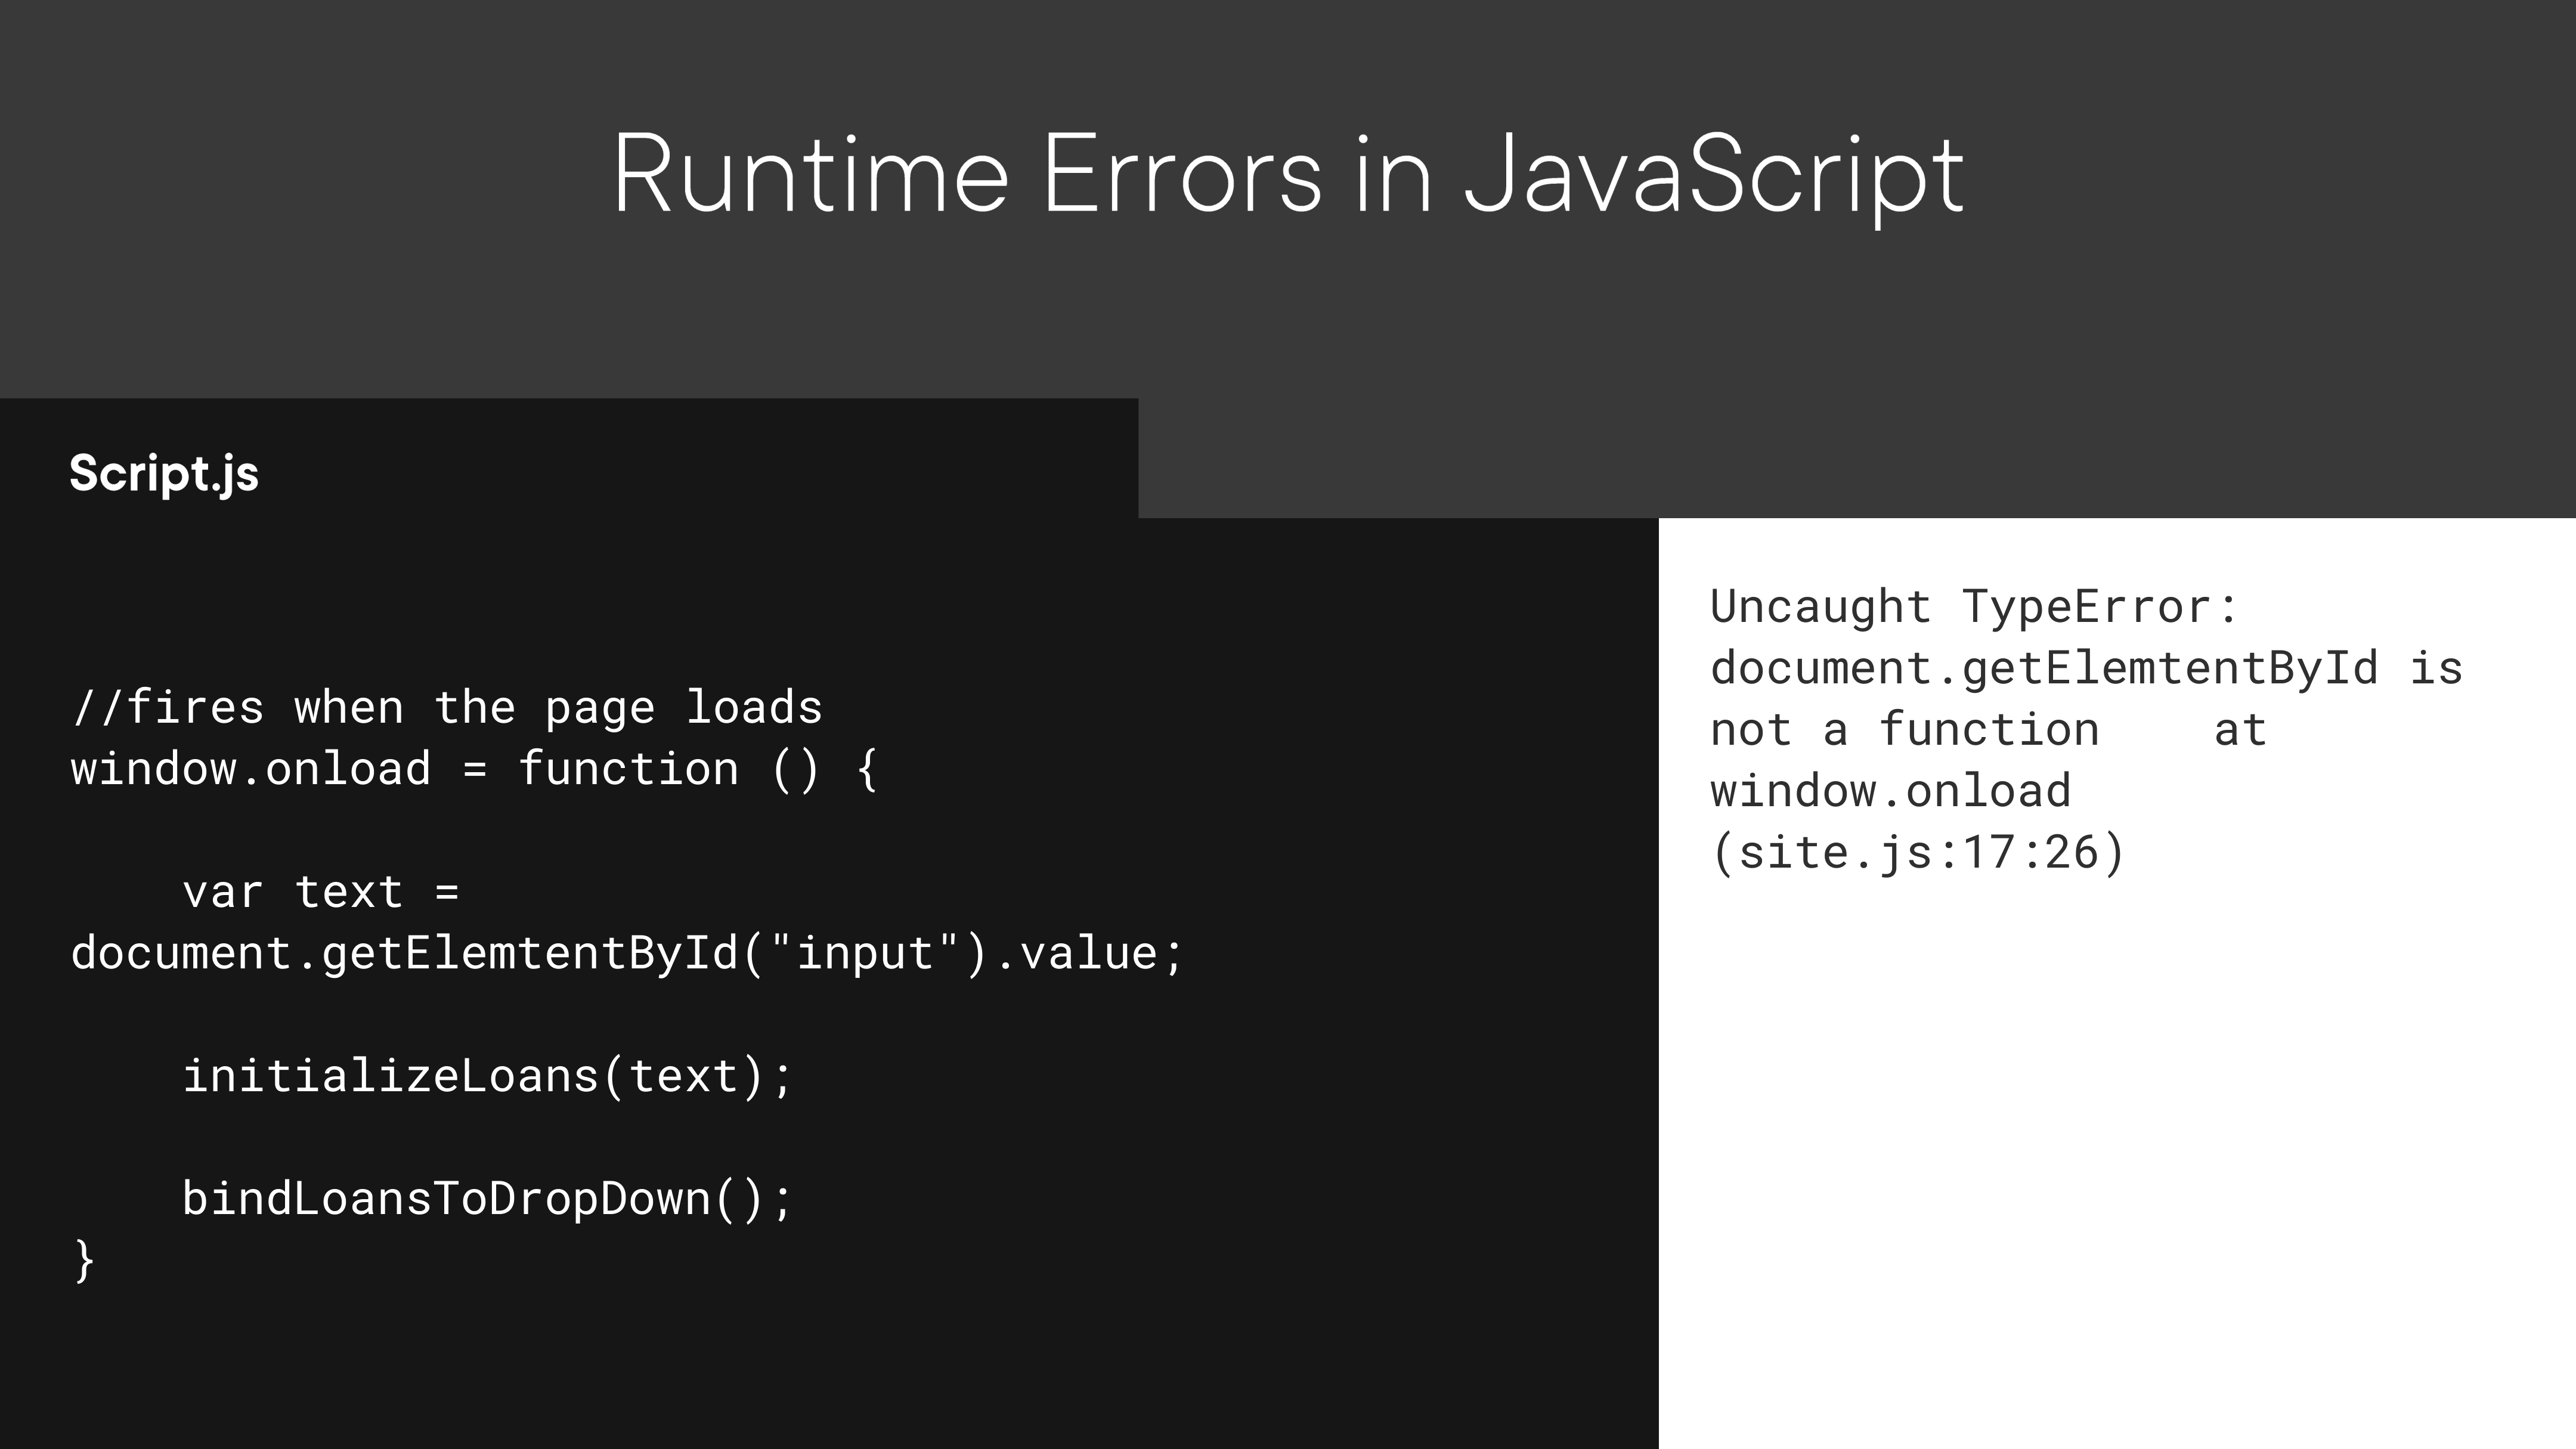

In [2]:
render_diagram(Path("assets/01-runtime-error-example.png"))

```js
// Buggy version — getElemtentById is a typo; the method does not exist on document
window.onload = function () {
  var text = document.getElemtentById("input").value; // TypeError thrown here
  initializeLoans(text);
  bindLoansToDropDown();
};

// Uncaught TypeError: document.getElemtentById is not a function
//     at window.onload (site.js:17:26)
```

```js
// Fixed version
window.onload = function () {
  var text = document.getElementById("input").value;
  initializeLoans(text);
  bindLoansToDropDown();
};
```

### Different Types of Errors

All built-in error types inherit from the base `Error` class.

| Base | Subtype | When thrown |
|---|---|---|
| `Error` | `ReferenceError` | Accessing a variable that has not been declared |
| `Error` | `TypeError` | A value is not of the expected type (e.g. calling a non-function) |
| `Error` | `SyntaxError` | Code that cannot be parsed (e.g. via `eval`) |
| `Error` | `RangeError` | A numeric value is outside the allowable range (e.g. invalid array length) |
| `Error` | `URIError` | `encodeURI`/`decodeURI` called with a malformed URI |
| `Error` | `EvalError` | Deprecated; relates to `eval()` misuse |
| `Error` | `InternalError` | Engine-level problem (e.g. stack overflow) — non-standard, Firefox only |

The base `Error` can also be thrown directly and is the recommended base class for custom error types.

### Summary

Key takeaways from this module:

- Always **expect errors** — defensive code assumes things can go wrong
- Errors in JavaScript are categorised as compile-time, runtime, syntax, or logic errors
- The **`Error` object** is the base for all built-in and custom error types
- **`try/catch/finally`** is the primary mechanism for structured error handling
- You can **extend the `Error` class** to create domain-specific error types
- Asynchronous code (Promises, `async/await`) requires its own error-handling patterns

### Further Reading

- [MDN JavaScript Errors reference](https://developer.mozilla.org/en-US/docs/Web/JavaScript/Reference/Errors)
- [MDN Control flow and error handling](https://developer.mozilla.org/en-US/docs/Web/JavaScript/Guide/Control_flow_and_error_handling#exception_handling_statements)